# N04: hybrid, and the full dev ladder

R5 adds the text branch (R3) and the image branch (R4). Their raw cosine similarities live on different scales, so
each is z-scored per query first, then averaged with equal weight (alpha = 0.5). Alpha is **not tuned**: tuning it on
judgments pooled from a few alphas would favour those alphas (ADR 0013).

This notebook ends the dev phase: full table, the 3 pre-registered comparisons, then `freeze()`.

In [1]:
from pathlib import Path

import pandas as pd

from deep_learning_project_waerniers_lamy_mahieddine.nlp import utils as u

c:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
paintings = u.load_corpus("dev")
descriptions = u.load_descriptions()
queries = u.QUERIES["text"].tolist()
scores = {
    "R0 random": u.rung_random(paintings, queries),
    "R1 metadata": u.rung_metadata(paintings, queries),
    "R2 description": u.rung_description(paintings, queries, descriptions),
    "R3 description+metadata": u.rung_description_metadata(paintings, queries, descriptions),
    "R4 siglip image": u.rung_siglip(paintings, queries),
    "R5 hybrid": u.rung_hybrid(paintings, queries, descriptions),
}
u.judge_with_llm("dev", scores, paintings)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3802.00it/s]
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.
Loading weights: 100%|██████████| 408/408 [00:01<00:00, 306.00it/s]


17 new (query, painting) pairs to grade with google/gemini-3.8-flash
784 judgments in C:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\results\nlp\qrels_dev.json, 0 failed


{'q01': {'s42_r0523': 0,
  's49_r0203': 0,
  's51_r0277': 0,
  's51_r0672': 0,
  's51_r0941': 0,
  's51_r0947': 0,
  's51_r1050': 0,
  's54_r0082': 0,
  's54_r0375': 2,
  's54_r0424': 2,
  's54_r0450': 2,
  's54_r0593': 2,
  's54_r0601': 2,
  's54_r0618': 2,
  's54_r0667': 2,
  's54_r0714': 0,
  's58_r0276': 0,
  's58_r0692': 0},
 'q02': {'s42_r0640': 0,
  's49_r0183': 0,
  's49_r0261': 0,
  's49_r0303': 0,
  's49_r0317': 0,
  's49_r0533': 0,
  's49_r0642': 0,
  's51_r0444': 0,
  's54_r0274': 1,
  's54_r0319': 2,
  's54_r0346': 2,
  's54_r0451': 1,
  's54_r0567': 2,
  's54_r0659': 1,
  's54_r0672': 2,
  's54_r0677': 2,
  's54_r0763': 1,
  's58_r0296': 0,
  's58_r0604': 0,
  's54_r0759': 2},
 'q03': {'s42_r0268': 1,
  's42_r0695': 2,
  's49_r0454': 2,
  's49_r1014': 1,
  's54_r0278': 0,
  's54_r0333': 0,
  's54_r0346': 0,
  's54_r0375': 0,
  's54_r0460': 0,
  's54_r0496': 0,
  's54_r0550': 0,
  's54_r0726': 0,
  's58_r0129': 1,
  's58_r0135': 1,
  's58_r0183': 1,
  's58_r0354': 2,
  's5

### Judging

Every painting in the new top 5 of a rung is graded by an LLM judge (`u.JUDGE_MODEL`, another model family than the
description generator). It sees **only the query and the image**, answers two yes/no questions (is the main subject
there? does it match the whole query?) and the grade follows by rule: 0, 1 or 2. Grades are saved in
`results/nlp/qrels_dev.json`; already graded pairs are never sent again. The judge is validated against 150 of your own
grades in N04 before any result is frozen.

## 0. Validate the judge (by hand, about 10 minutes)

A seeded random sample of 150 graded (query, painting) pairs, drawn from every rung. Open the page, grade each pair with
the keyboard on the same scale (0 subject absent, 1 subject there but part of the query missing, 2 whole match), click
*export JSON*, then run the next cells. The judge is accepted if the weighted kappa with your grades is at least
0.6 ("substantial agreement"); otherwise `freeze()` refuses and dev must be graded by hand.

In [3]:
u.write_calibration_page("dev", paintings)

150 pairs: open C:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\data\wikiart_genre5\nlp\calibration_dev.html in a browser, grade with keys 0/1/2, then click 'export JSON'.


WindowsPath('C:/Users/Vincent/GitHub/Vincent-20-100/deep-learning-project-waerniers-lamy/data/wikiart_genre5/nlp/calibration_dev.html')

In [5]:
u.import_calibration("dev", Path.home() / "Downloads" / "calibration_dev.json")
u.judge_agreement("dev")

judge   0  1   2
human           
0      63  4   1
1      18  9   5
2       6  8  36


{'kappa': 0.6502997430773623, 'n': 150, 'exact_agreement': 0.72}

## 1. The dev ladder

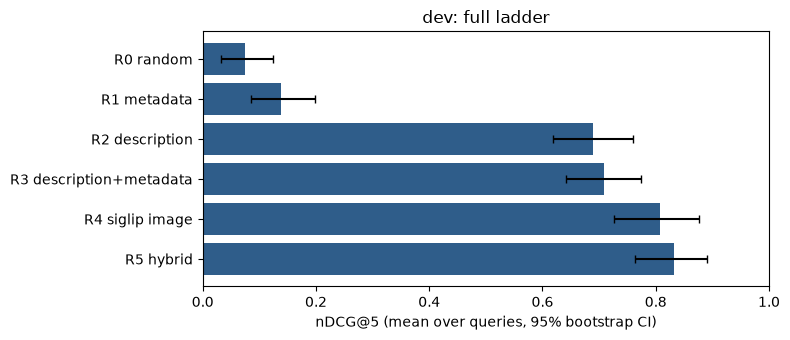

,rung,queries,nDCG@5,nDCG low,nDCG high,Success@5,Success low,Success high,judged@5
0,R0 random,39,0.074,0.033,0.124,0.128,0.026,0.231,1.0
1,R1 metadata,39,0.139,0.086,0.198,0.256,0.128,0.385,1.0
2,R2 description,39,0.689,0.619,0.760,0.923,0.821,1.000,1.0
3,R3 description+metadata,39,0.708,0.641,0.774,0.923,0.821,1.000,1.0
4,R4 siglip image,39,0.808,0.726,0.877,0.897,0.795,0.974,1.0
5,R5 hybrid,39,0.832,0.764,0.891,0.949,0.872,1.000,1.0


In [6]:
per_query = u.per_query_scores("dev", scores, paintings)
table = u.summary_table(per_query)
u.plot_ladder(table, "dev: full ladder")
table.to_csv(u.RESULTS_DIR / "dev_summary.csv", index=False)
per_query.to_csv(u.RESULTS_DIR / "dev_per_query.csv", index=False)
table

## 2. Pre-registered comparisons

Only these three, fixed before seeing results, Holm-corrected: visual text vs metadata, visual embedding vs metadata,
and fusion vs the better single branch (R3 or R4, whichever is higher on dev; that choice is frozen for Museum B).
With 40 queries, differences of a few nDCG points are not detectable: read the confidence intervals, not only p.

In [7]:
means = table.set_index("rung")["nDCG@5"]
best_single = max(["R3 description+metadata", "R4 siglip image"], key=means.get)
u.compare(per_query, [("R2 description", "R1 metadata"), ("R4 siglip image", "R1 metadata"), ("R5 hybrid", best_single)])

,system,reference,delta nDCG@5,p,p (Holm)
0,R2 description,R1 metadata,0.5508,0.0001,0.0003
1,R4 siglip image,R1 metadata,0.6695,0.0001,0.0003
2,R5 hybrid,R4 siglip image,0.0240,0.5413,0.5413


## 3. By query category (descriptive, no p-values: about 10 queries per category)

In [8]:
per_query.groupby(["rung", "category"])["ndcg@5"].mean().unstack().round(3)

category,compound,mood_colour,object,scene
rung,,,,
R0 random,0.014,0.233,0.042,0.020
R1 metadata,0.146,0.305,0.084,0.043
R2 description,0.592,0.700,0.820,0.624
R3 description+metadata,0.633,0.735,0.802,0.646
R4 siglip image,0.824,0.876,0.747,0.799
R5 hybrid,0.812,0.891,0.843,0.784


## 4. Limits of the measurement

- **Pool miss rate**: R0's random paintings that no real rung put in its top 5 were judged too. The share of them
  that is relevant estimates how many relevant paintings the pool never saw (they count as 0 for everyone).
- **Latency** on this CPU, for one query, corpus embeddings already computed.
- The grades come from an LLM judge: read them with the kappa of section 0 (agreement with a human, not truth).

In [9]:
qrels = u.load_qrels("dev")
real = [s for name, s in scores.items() if name != "R0 random"]
outside = [qrels[qid][pid]
           for qi, qid in enumerate(u.QUERIES["query_id"])
           for pid in u.top_k_ids(scores["R0 random"], paintings)[qi]
           if all(pid not in u.top_k_ids(s, paintings)[qi] for s in real) and pid in qrels.get(qid, {})]
print(f"pool miss rate: {sum(g >= 1 for g in outside) / len(outside):.3f} over {len(outside)} random paintings")

rungs = {
    "R1 metadata": (u.rung_metadata, paintings),
    "R2 description": (u.rung_description, paintings, descriptions),
    "R4 siglip image": (u.rung_siglip, paintings),
    "R5 hybrid": (u.rung_hybrid, paintings, descriptions),
}
pd.Series({name: u.latency_ms(fn, *args) for name, (fn, *args) in rungs.items()}, name="median ms / query").round(1)

pool miss rate: 0.108 over 195 random paintings


R1 metadata         34.5
R2 description      12.6
R4 siglip image     82.3
R5 hybrid          114.6
Name: median ms / query, dtype: float64

## 5. Freeze

Writes `results/nlp/frozen_config.json`: models, prompts, judge, alpha, the judge's kappa, and hashes of the
descriptions and the queries. Refuses if the judge kappa is below 0.6. N05
refuses to run if any of them changed afterwards. Commit the frozen config with the dev judgments before opening N05.

In [10]:
u.freeze(best_single)
print(Path(u.FROZEN_CONFIG).read_text())

judge   0  1   2
human           
0      63  4   1
1      18  9   5
2       6  8  36
{
 "vlm_model": "qwen/qwen3-vl-8b-instruct",
 "vlm_prompt": "5b7ef56517d7028a",
 "text_model": "sentence-transformers/all-MiniLM-L6-v2",
 "siglip_model": "google/siglip-base-patch16-224",
 "hybrid_alpha": 0.5,
 "judge_model": "google/gemini-3.8-flash",
 "judge_prompt": "5fc94ee28ff3e01a",
 "descriptions": "a2d8b7e73e82dfa5",
 "queries": "0a971ee06920da40",
 "best_single": "R4 siglip image",
 "judge_kappa_dev": 0.65
}
